# Problem 4: Credit Card Default Prediction
## Part 2: Model Development & Hyperparameter Tuning

**Candidate:** Chetsadaphon Kanthiya 
**Dataset:** UCI Default of Credit Card Clients (30,000 records) 

---

## Requirements Coverage:
 **Q3 (27%):** Model comparison - Baseline + tree-based models with hyperparameter tuning 

**Models:**
- Logistic Regression (baseline)
- Decision Tree
- LightGBM
- XGBoost

**Workflow summary:** Compare engineered-feature sets using training-only stratified 5-fold CV, use the selected set for model tuning/comparison, then save the untouched holdout for notebook 3.

**Models:** Logistic Regression baseline, Decision Tree, LightGBM, and XGBoost. Optuna tuning uses a fixed seed.


In [1]:
# โหลดไลบรารีสำหรับฝึกโมเดลและประเมินผล
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
 roc_auc_score, average_precision_score, f1_score,
 precision_score, recall_score, roc_curve, precision_recall_curve,
 confusion_matrix, classification_report
)
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import xgboost as xgb
import optuna
from optuna.samplers import TPESampler
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

print(" Libraries imported")

 Libraries imported


## 1. Load Prepared Data

In [2]:
# โหลดข้อมูล สร้าง features และแยก train/test สำหรับการฝึก
# Load and preprocess data using the shared feature pipeline
from preprocessing import load_and_clean_data, engineer_features, select_features
from sklearn.model_selection import train_test_split

# Load dataset
df_raw = load_and_clean_data('data/default of credit card clients.xls')
df = engineer_features(df_raw)

# Load the 19-feature candidate pool (include SEX for subgroup analysis); CV below selects the final model subset.
X, y = select_features(df, include_sex=True, include_education=True, include_marriage=False)

# Train/test split (70/30, stratified)
SEED = 42
OUTPUT_DIR = os.path.abspath('output')
DATA_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'data')
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'models')
RESULTS_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'results')
for output_dir in (DATA_OUTPUT_DIR, MODEL_OUTPUT_DIR, RESULTS_OUTPUT_DIR):
    os.makedirs(output_dir, exist_ok=True)
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Convert y to numpy arrays (fix Optuna indexing bug)
y_train = y_train.values if hasattr(y_train, 'values') else y_train
y_test = y_test.values if hasattr(y_test, 'values') else y_test

print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Default rate - Train: {y_train.mean()*100:.2f}%, Test: {y_test.mean()*100:.2f}%')
print(f'\nFeatures ({X_train.shape[1]}):')
print(list(X_train.columns))

# The feature-set comparison below chooses which subset enters model tuning.
assert X_train.shape[1] == 19, f'Expected 19 candidate features, got {X_train.shape[1]}!'
print('\n Loaded 19 candidate features (12 core + 6 engineered + 1 fairness)')
print(f' y_train type: {type(y_train)} (should be numpy.ndarray)')


Train: (21000, 19), Test: (9000, 19)
Default rate - Train: 22.12%, Test: 22.12%

Features (19):
['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT6', 'PAY_AMT1', 'AGE', 'EDUCATION', 'UTIL_RATE', 'PAY_RATIO', 'AVG_DELAY', 'NUM_DELAYS', 'BILL_TREND', 'PAY_VOLATILITY', 'SEX']

 Loaded 19 candidate features (12 core + 6 engineered + 1 fairness)
 y_train type: <class 'numpy.ndarray'> (should be numpy.ndarray)


## 2. Compare Engineered Feature Sets

Use the same stratified folds and a scaled logistic-regression baseline for every feature set. Compare the 13-feature core, each engineered feature added alone, all six added together, and leave-one-engineered-feature-out variants. Use the one-standard-error rule on mean ROC-AUC to prefer the smallest set whose mean is within one standard error of the best; use mean PR-AUC as a tie-breaker. This is a selection heuristic, not a significance test. This is training-only feature selection; the holdout remains reserved for notebook 3.

In [3]:
# Compare feature sets on identical training-only folds before final model tuning.
import json

ENGINEERED_FEATURES = [
    'UTIL_RATE', 'PAY_RATIO', 'AVG_DELAY',
    'NUM_DELAYS', 'BILL_TREND', 'PAY_VOLATILITY',
]
core_features = [name for name in X_train.columns if name not in ENGINEERED_FEATURES]
feature_sets = {'core_only': core_features}
for feature in ENGINEERED_FEATURES:
    feature_sets[f'core_plus_{feature.lower()}'] = core_features + [feature]
feature_sets['core_plus_all_engineered'] = core_features + ENGINEERED_FEATURES
for feature in ENGINEERED_FEATURES:
    feature_sets[f'all_except_{feature.lower()}'] = [
        name for name in X_train.columns if name != feature
    ]

feature_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
feature_cv_splits = list(feature_cv.split(X_train, y_train))
feature_rows = []
for set_name, columns in feature_sets.items():
    fold_roc_auc = []
    fold_pr_auc = []
    for train_idx, val_idx in feature_cv_splits:
        estimator = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced'),
        )
        estimator.fit(X_train.iloc[train_idx][columns], y_train[train_idx])
        probabilities = estimator.predict_proba(X_train.iloc[val_idx][columns])[:, 1]
        fold_roc_auc.append(roc_auc_score(y_train[val_idx], probabilities))
        fold_pr_auc.append(average_precision_score(y_train[val_idx], probabilities))
    feature_rows.append({
        'feature_set': set_name,
        'feature_count': len(columns),
        'engineered_features': ', '.join(name for name in ENGINEERED_FEATURES if name in columns) or 'none',
        'mean_roc_auc': float(np.mean(fold_roc_auc)),
        'std_roc_auc': float(np.std(fold_roc_auc, ddof=1)),
        'mean_pr_auc': float(np.mean(fold_pr_auc)),
        'std_pr_auc': float(np.std(fold_pr_auc, ddof=1)),
    })

feature_comparison_df = pd.DataFrame(feature_rows).sort_values(
    ['mean_roc_auc', 'mean_pr_auc', 'feature_count'],
    ascending=[False, False, True],
).reset_index(drop=True)
top_feature_row = feature_comparison_df.iloc[0]
one_se_cutoff = top_feature_row['mean_roc_auc'] - top_feature_row['std_roc_auc'] / np.sqrt(len(feature_cv_splits))
eligible_feature_sets = feature_comparison_df[
    feature_comparison_df['mean_roc_auc'] >= one_se_cutoff
].sort_values(
    ['feature_count', 'mean_pr_auc', 'mean_roc_auc'],
    ascending=[True, False, False],
)
selected_feature_row = eligible_feature_sets.iloc[0]
best_feature_set = selected_feature_row['feature_set']
selected_features = feature_sets[best_feature_set]
feature_comparison_df['delta_roc_auc_vs_core'] = (
    feature_comparison_df['mean_roc_auc']
    - feature_comparison_df.loc[feature_comparison_df['feature_set'] == 'core_only', 'mean_roc_auc'].iloc[0]
)
feature_comparison_df['delta_roc_auc_vs_all_engineered'] = (
    feature_comparison_df['mean_roc_auc']
    - feature_comparison_df.loc[
        feature_comparison_df['feature_set'] == 'core_plus_all_engineered', 'mean_roc_auc'
    ].iloc[0]
)
feature_comparison_df['within_one_standard_error'] = (
    feature_comparison_df['mean_roc_auc'] >= one_se_cutoff
)
feature_comparison_df['selected_by_one_se_rule'] = (
    feature_comparison_df['feature_set'] == best_feature_set
)
comparison_path = os.path.join(RESULTS_OUTPUT_DIR, 'feature_set_comparison.csv')
feature_comparison_df.to_csv(comparison_path, index=False)
selection = {
    'selection_metric': 'smallest feature set within one standard error of the highest mean 5-fold training ROC-AUC; ties use higher PR-AUC',
    'best_cv_feature_set': top_feature_row['feature_set'],
    'best_cv_mean_roc_auc': float(top_feature_row['mean_roc_auc']),
    'one_standard_error_cutoff': float(one_se_cutoff),
    'selected_feature_set': best_feature_set,
    'selected_features': selected_features,
    'feature_count': len(selected_features),
    'mean_roc_auc': float(selected_feature_row['mean_roc_auc']),
    'mean_pr_auc': float(selected_feature_row['mean_pr_auc']),
    'comparison_file': 'feature_set_comparison.csv',
}
with open(os.path.join(RESULTS_OUTPUT_DIR, 'selected_features.json'), 'w', encoding='utf-8') as file:
    json.dump(selection, file, indent=2)

print('FEATURE-SET COMPARISON (training-only 5-fold CV)')
print(feature_comparison_df.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
print(f'\nHighest mean ROC-AUC: {top_feature_row["feature_set"]} ({top_feature_row["mean_roc_auc"]:.4f})')
print(f'One-standard-error cutoff: {one_se_cutoff:.4f}')
print(f'Selected parsimonious set: {best_feature_set} ({len(selected_features)} features; ROC-AUC={selected_feature_row["mean_roc_auc"]:.4f}, PR-AUC={selected_feature_row["mean_pr_auc"]:.4f})')
print(f'Comparison saved: {comparison_path}')
print('Selection saved: ' + os.path.join(RESULTS_OUTPUT_DIR, 'selected_features.json'))

# Keep only the selected feature set for all subsequent tuning and OOF comparisons.
X_train = X_train.loc[:, selected_features].copy()
X_test = X_test.loc[:, selected_features].copy()
print(f'Feature selection applied to modeling data: {X_train.shape[1]} features')

FEATURE-SET COMPARISON (training-only 5-fold CV)
              feature_set  feature_count                                                     engineered_features  mean_roc_auc  std_roc_auc  mean_pr_auc  std_pr_auc  delta_roc_auc_vs_core  delta_roc_auc_vs_all_engineered  within_one_standard_error  selected_by_one_se_rule
     all_except_pay_ratio             18            UTIL_RATE, AVG_DELAY, NUM_DELAYS, BILL_TREND, PAY_VOLATILITY        0.7549       0.0109       0.5120      0.0127                 0.0320                           0.0001                       True                    False
     all_except_avg_delay             18            UTIL_RATE, PAY_RATIO, NUM_DELAYS, BILL_TREND, PAY_VOLATILITY        0.7548       0.0108       0.5118      0.0125                 0.0319                           0.0000                       True                    False
 core_plus_all_engineered             19 UTIL_RATE, PAY_RATIO, AVG_DELAY, NUM_DELAYS, BILL_TREND, PAY_VOLATILITY        0.7548      

## 3. Feature Scaling

Scale features for Logistic Regression (tree models don't need scaling)

In [4]:
# ปรับสเกลโดย fit เฉพาะ train แล้วใช้ค่าชุดเดิมกับ test
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Convert back to DataFrame for consistency
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)

print(" Features scaled (mean=0, std=1)")

 Features scaled (mean=0, std=1)


## 4. Baseline Model: Logistic Regression

In [5]:
# ฝึก Logistic Regression เป็นโมเดล baseline
# Train baseline Logistic Regression
lr_model = LogisticRegression(
 max_iter=1000,
 random_state=42,
 class_weight='balanced'
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression baseline fitted on training data; holdout metrics are reserved for notebook 3.")

Logistic Regression baseline fitted on training data; holdout metrics are reserved for notebook 3.


## 5. Decision Tree with Hyperparameter Tuning

Tune Decision Tree using Optuna for fair comparison

In [6]:
# ใช้ stratified CV และ Optuna หา hyperparameters ของ Decision Tree
# Setup cross-validation for Decision Tree
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective_dt(trial):
    """Optuna objective for Decision Tree."""
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 50),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'random_state': 42,
        'class_weight': 'balanced'
    }

    scores = []
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model = DecisionTreeClassifier(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(y_val, y_pred))

    return np.mean(scores)

print("Starting Decision Tree hyperparameter tuning (50 trials)...")
study_dt = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_dt.optimize(objective_dt, n_trials=50, show_progress_bar=True)

print(f"\n Decision Tree Best ROC-AUC: {study_dt.best_value:.4f}")
print(f"Best params: {study_dt.best_params}")

[I 2026-11-12 01:38:08,254] A new study created in memory with name: no-name-5a97555d-6d8d-4003-95c1-79c200eb6efe


Starting Decision Tree hyperparameter tuning (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-11-12 01:38:08,332] Trial 0 finished with value: 0.7593084216286978 and parameters: {'max_depth': 9, 'min_samples_split': 48, 'min_samples_leaf': 15, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.7593084216286978.


[I 2026-11-12 01:38:08,474] Trial 1 finished with value: 0.7658456955619053 and parameters: {'max_depth': 4, 'min_samples_split': 44, 'min_samples_leaf': 13, 'max_features': None}. Best is trial 1 with value: 0.7658456955619053.


[I 2026-11-12 01:38:08,870] Trial 2 finished with value: 0.6899386558789294 and parameters: {'max_depth': 17, 'min_samples_split': 12, 'min_samples_leaf': 4, 'max_features': None}. Best is trial 1 with value: 0.7658456955619053.


... (21 outputs left out)

[I 2026-11-12 01:38:16,393] Trial 44 finished with value: 0.7693576226347665 and parameters: {'max_depth': 5, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': None}. Best is trial 12 with value: 0.7697517308875103.


[I 2026-11-12 01:38:16,603] Trial 45 finished with value: 0.7676939171549966 and parameters: {'max_depth': 6, 'min_samples_split': 10, 'min_samples_leaf': 3, 'max_features': None}. Best is trial 12 with value: 0.7697517308875103.
[I 2026-11-12 01:38:16,681] Trial 46 finished with value: 0.7557051085657006 and parameters: {'max_depth': 8, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': 'log2'}. Best is trial 12 with value: 0.7697517308875103.


[I 2026-11-12 01:38:16,908] Trial 47 finished with value: 0.7661302196060957 and parameters: {'max_depth': 7, 'min_samples_split': 50, 'min_samples_leaf': 5, 'max_features': None}. Best is trial 12 with value: 0.7697517308875103.
[I 2026-11-12 01:38:16,956] Trial 48 finished with value: 0.7367002450671476 and parameters: {'max_depth': 3, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 'sqrt'}. Best is trial 12 with value: 0.7697517308875103.


[I 2026-11-12 01:38:17,160] Trial 49 finished with value: 0.7676468913790137 and parameters: {'max_depth': 6, 'min_samples_split': 2, 'min_samples_leaf': 3, 'max_features': None}. Best is trial 12 with value: 0.7697517308875103.

 Decision Tree Best ROC-AUC: 0.7698
Best params: {'max_depth': 6, 'min_samples_split': 27, 'min_samples_leaf': 10, 'max_features': None}


In [7]:
# ฝึก Decision Tree ด้วยพารามิเตอร์ที่ดีที่สุดจากการค้นหา
# Train Decision Tree with best parameters
dt_params = study_dt.best_params.copy()
dt_params.update({
 'random_state': 42,
 'class_weight': 'balanced'
})

dt_model = DecisionTreeClassifier(**dt_params)
dt_model.fit(X_train, y_train)

print(" Decision Tree fitted on training data")

 Decision Tree fitted on training data


## 6. Hyperparameter Tuning with Optuna

Tune LightGBM and XGBoost using Bayesian optimization

In [8]:
# ค้นหา hyperparameters ของ LightGBM ด้วย ROC-AUC บน CV
# Setup cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective_lgb(trial):
    """Optuna objective for LightGBM."""
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'num_leaves': trial.suggest_int('num_leaves', 20, 150),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
        'n_estimators': 500,
        'random_state': 42,
        'is_unbalance': True,
    }

    scores = []
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)],
            callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)],
        )
        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(y_val, y_pred))

    return np.mean(scores)

print("Starting LightGBM hyperparameter tuning (50 trials)...")
study_lgb = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_lgb.optimize(objective_lgb, n_trials=50, show_progress_bar=True)

print(f"\n LightGBM Best ROC-AUC: {study_lgb.best_value:.4f}")
print(f"Best params: {study_lgb.best_params}")

[I 2026-11-12 01:38:17,217] A new study created in memory with name: no-name-07882a16-2d2e-4af8-8ad6-03b58eb87035


Starting LightGBM hyperparameter tuning (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]

Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[39]	valid_0's auc: 0.781784
Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[42]	valid_0's auc: 0.797233
Training until validation scores don't improve for 50 rounds


... (222 outputs left out)

Early stopping, best iteration is:
[131]	valid_0's auc: 0.797025
Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[105]	valid_0's auc: 0.777542
Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[138]	valid_0's auc: 0.77965
Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[86]	valid_0's auc: 0.779435
[I 2026-11-12 01:39:41,963] Trial 49 finished with value: 0.7840108741759383 and parameters: {'learning_rate': 0.048246680061256944, 'num_leaves': 99, 'max_depth': 4, 'min_child_samples': 20, 'subsample': 0.6677597848001512, 'colsample_bytree': 0.8640087741295207, 'reg_alpha': 0.7499863419982691, 'reg_lambda': 0.6822272860003574}. Best is trial 42 with value: 0.7850447830841472.

 LightGBM Best ROC-AUC: 0.7850
Best params: {'learning_rate': 0.028802902812904388, 'num_leaves': 24, 'max_depth': 6, 'min_child_samples': 17, 'subsample': 0.6001911036258377, 'colsample_bytree': 0.8842320373135321, 'reg_alpha': 0.6391562089306192, 'reg_lambda': 0.5867876848953455}


In [9]:
# ค้นหา hyperparameters ของ XGBoost ด้วย ROC-AUC บน CV
def objective_xgb(trial):
    """Optuna objective for XGBoost."""
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'tree_method': 'hist',
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
        'n_estimators': 500,
        'random_state': 42,
        'scale_pos_weight': (y_train == 0).sum() / (y_train == 1).sum(),
    }

    scores = []
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model = xgb.XGBClassifier(**params)
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)],
            early_stopping_rounds=50,
            verbose=False,
        )
        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(y_val, y_pred))

    return np.mean(scores)

print("Starting XGBoost hyperparameter tuning (50 trials)...")
study_xgb = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

print(f"\n XGBoost Best ROC-AUC: {study_xgb.best_value:.4f}")
print(f"Best params: {study_xgb.best_params}")

[I 2026-11-12 01:39:41,970] A new study created in memory with name: no-name-234e5dd1-3f46-4296-8efc-5aa382436bc1


Starting XGBoost hyperparameter tuning (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-11-12 01:39:43,004] Trial 0 finished with value: 0.7788817737767293 and parameters: {'learning_rate': 0.04370861069626263, 'max_depth': 12, 'min_child_weight': 8, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'gamma': 0.15599452033620265, 'reg_alpha': 0.05808361216819946, 'reg_lambda': 0.8661761457749352}. Best is trial 0 with value: 0.7788817737767293.


[I 2026-11-12 01:39:43,957] Trial 1 finished with value: 0.7664031270660161 and parameters: {'learning_rate': 0.0641003510568888, 'max_depth': 10, 'min_child_weight': 1, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9329770563201687, 'gamma': 0.21233911067827616, 'reg_alpha': 0.18182496720710062, 'reg_lambda': 0.18340450985343382}. Best is trial 0 with value: 0.7788817737767293.


[I 2026-11-12 01:39:44,856] Trial 2 finished with value: 0.7826424866203605 and parameters: {'learning_rate': 0.0373818018663584, 'max_depth': 8, 'min_child_weight': 5, 'subsample': 0.7164916560792167, 'colsample_bytree': 0.8447411578889518, 'gamma': 0.13949386065204183, 'reg_alpha': 0.29214464853521815, 'reg_lambda': 0.3663618432936917}. Best is trial 2 with value: 0.7826424866203605.


... (43 outputs left out)

[I 2026-11-12 01:40:20,735] Trial 46 finished with value: 0.7819312094180552 and parameters: {'learning_rate': 0.0839381954368637, 'max_depth': 7, 'min_child_weight': 2, 'subsample': 0.619495055168308, 'colsample_bytree': 0.7152001050666495, 'gamma': 0.5081576667727832, 'reg_alpha': 0.22972917771515158, 'reg_lambda': 0.8431457978954017}. Best is trial 41 with value: 0.7855659168759352.


[I 2026-11-12 01:40:21,877] Trial 47 finished with value: 0.7808078561017837 and parameters: {'learning_rate': 0.028448516004867544, 'max_depth': 9, 'min_child_weight': 1, 'subsample': 0.6579100326326744, 'colsample_bytree': 0.8046592841351862, 'gamma': 0.3948976131643781, 'reg_alpha': 0.37976836367633515, 'reg_lambda': 0.5209579953143054}. Best is trial 41 with value: 0.7855659168759352.


[I 2026-11-12 01:40:23,017] Trial 48 finished with value: 0.7835989626028257 and parameters: {'learning_rate': 0.04168252879466233, 'max_depth': 6, 'min_child_weight': 3, 'subsample': 0.9510201025377552, 'colsample_bytree': 0.7620874059849665, 'gamma': 0.2067630084800893, 'reg_alpha': 0.2584415673909598, 'reg_lambda': 0.392668423100056}. Best is trial 41 with value: 0.7855659168759352.


[I 2026-11-12 01:40:23,660] Trial 49 finished with value: 0.7840972252159517 and parameters: {'learning_rate': 0.0916764696625342, 'max_depth': 5, 'min_child_weight': 2, 'subsample': 0.6148782959207765, 'colsample_bytree': 0.7974357898191163, 'gamma': 0.4573273568982459, 'reg_alpha': 0.5996068121061823, 'reg_lambda': 0.5913608322650208}. Best is trial 41 with value: 0.7855659168759352.

 XGBoost Best ROC-AUC: 0.7856
Best params: {'learning_rate': 0.08734056842882651, 'max_depth': 4, 'min_child_weight': 3, 'subsample': 0.6039489176318604, 'colsample_bytree': 0.7481489587178267, 'gamma': 0.45110638563143196, 'reg_alpha': 0.6105443519032435, 'reg_lambda': 0.6947272898264866}


## 7. Train Final Models with Best Hyperparameters

In [10]:
# ฝึก LightGBM ตัวสุดท้ายด้วยพารามิเตอร์ที่เลือกได้
# LightGBM final model
lgb_params = study_lgb.best_params.copy()
lgb_params.update({
 'objective': 'binary',
 'metric': 'auc',
 'verbosity': -1,
 'n_estimators': 500,
 'random_state': 42,
 'is_unbalance': True
})

lgb_model = lgb.LGBMClassifier(**lgb_params)
lgb_model.fit(X_train, y_train)

print(" LightGBM fitted on training data")

 LightGBM fitted on training data


In [11]:
# ฝึก XGBoost ตัวสุดท้ายด้วยพารามิเตอร์ที่เลือกได้
# XGBoost final model
xgb_params = study_xgb.best_params.copy()
xgb_params.update({
 'objective': 'binary:logistic',
 'eval_metric': 'auc',
 'tree_method': 'hist',
 'n_estimators': 500,
 'random_state': 42,
 'scale_pos_weight': (y_train == 0).sum() / (y_train == 1).sum()
})

xgb_model = xgb.XGBClassifier(**xgb_params)
xgb_model.fit(X_train, y_train)

print(" XGBoost fitted on training data")

 XGBoost fitted on training data


## 8. Model Comparison

In [12]:
# สร้าง out-of-fold predictions เพื่อเปรียบเทียบโมเดลโดยไม่แตะ holdout
cv_models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced')
    ),
    'Decision Tree': DecisionTreeClassifier(**dt_params),
    'LightGBM': lgb.LGBMClassifier(**lgb_params),
    'XGBoost': xgb.XGBClassifier(**xgb_params),
}
final_models = {
    'Logistic Regression': lr_model,
    'Decision Tree': dt_model,
    'LightGBM': lgb_model,
    'XGBoost': xgb_model,
}

models_results = {}
comparison_rows = []
for name, estimator in cv_models.items():
    oof_proba = cross_val_predict(
        estimator, X_train, y_train, cv=cv, method='predict_proba', n_jobs=1
    )[:, 1]
    oof_pred = (oof_proba >= 0.5).astype(int)
    models_results[name] = {
        'y_pred': oof_pred,
        'y_proba': oof_proba,
        'model': final_models[name],
    }
    comparison_rows.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_train, oof_proba),
        'PR-AUC': average_precision_score(y_train, oof_proba),
        'F1': f1_score(y_train, oof_pred),
        'Precision': precision_score(y_train, oof_pred, zero_division=0),
        'Recall': recall_score(y_train, oof_pred, zero_division=0),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    'ROC-AUC', ascending=False
).reset_index(drop=True)
best_model_name = comparison_df.iloc[0]['Model']

print('MODEL COMPARISON (5-fold out-of-fold training predictions)')
print(comparison_df.to_string(index=False))
comparison_df.to_csv(os.path.join(RESULTS_OUTPUT_DIR, 'cross_validation_model_comparison.csv'), index=False)

MODEL COMPARISON (5-fold out-of-fold training predictions)
              Model  ROC-AUC   PR-AUC       F1  Precision   Recall
           LightGBM 0.780367 0.553961 0.532487   0.465038 0.622820
      Decision Tree 0.770361 0.538614 0.522940   0.440129 0.644133
            XGBoost 0.770066 0.540494 0.521509   0.452887 0.614639
Logistic Regression 0.754558 0.510997 0.528894   0.480478 0.588159


## 9. Bootstrap Confidence Intervals (Training OOF)

Calculate 95% CI for ROC-AUC using bootstrap (1000 iterations)

In [13]:
# Bootstrap ROC-AUC เพื่อสร้างช่วงความเชื่อมั่นของแต่ละโมเดล
def bootstrap_auc(y_true, y_proba, n_iterations=1000, alpha=0.05):
    """Calculate a bootstrap confidence interval for ROC-AUC."""
    np.random.seed(42)
    n_samples = len(y_true)
    aucs = []

    for _ in range(n_iterations):
        indices = np.random.choice(n_samples, n_samples, replace=True)
        if len(np.unique(y_true[indices])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[indices], y_proba[indices]))

    aucs = np.array(aucs)
    mean_auc = np.mean(aucs)
    ci_lower = np.percentile(aucs, 100 * alpha / 2)
    ci_upper = np.percentile(aucs, 100 * (1 - alpha / 2))
    return mean_auc, ci_lower, ci_upper

print("Calculating bootstrap confidence intervals (1000 iterations)...\n")
bootstrap_results = []
for name, results in models_results.items():
    mean_auc, ci_lower, ci_upper = bootstrap_auc(y_train, results['y_proba'])
    bootstrap_results.append({
        'Model': name,
        'Mean AUC': mean_auc,
        'CI Lower': ci_lower,
        'CI Upper': ci_upper,
        'CI Width': ci_upper - ci_lower,
    })
    print(f"{name}:")
    print(f" Mean AUC: {mean_auc:.4f}")
    print(f" 95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]\n")

bootstrap_df = pd.DataFrame(bootstrap_results)
bootstrap_df.to_csv(os.path.join(RESULTS_OUTPUT_DIR, 'training_bootstrap_confidence_intervals.csv'), index=False)
print(f" Saved: {os.path.join(RESULTS_OUTPUT_DIR, 'training_bootstrap_confidence_intervals.csv')}")

Calculating bootstrap confidence intervals (1000 iterations)...



Logistic Regression:
 Mean AUC: 0.7547
 95% CI: [0.7470, 0.7628]



Decision Tree:
 Mean AUC: 0.7705
 95% CI: [0.7629, 0.7782]



LightGBM:
 Mean AUC: 0.7806
 95% CI: [0.7729, 0.7889]



XGBoost:
 Mean AUC: 0.7702
 95% CI: [0.7626, 0.7788]

 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\results\training_bootstrap_confidence_intervals.csv


## 10. Visualization: Model Comparison

In [14]:
# วาด ROC และ Precision-Recall curves เปรียบเทียบโมเดล
# ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ROC curve
ax = axes[0]
for name, results in models_results.items():
 fpr, tpr, _ = roc_curve(y_train, results['y_proba'])
 auc = roc_auc_score(y_train, results['y_proba'])
 ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.500)', linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves - Model Comparison', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)

# Precision-Recall curve
ax = axes[1]
baseline_precision = y_train.mean()
for name, results in models_results.items():
 precision, recall, _ = precision_recall_curve(y_train, results['y_proba'])
 ap = average_precision_score(y_train, results['y_proba'])
 ax.plot(recall, precision, label=f'{name} (AP={ap:.3f})', linewidth=2)

ax.axhline(y=baseline_precision, color='k', linestyle='--', 
 label=f'Baseline (AP={baseline_precision:.3f})', linewidth=1)
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves', fontsize=14, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../../report/q4/q4_08_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(" Saved: q4_08_roc_pr_curves.png")

<Figure size 1500x500 with 2 Axes>

 Saved: q4_08_roc_pr_curves.png


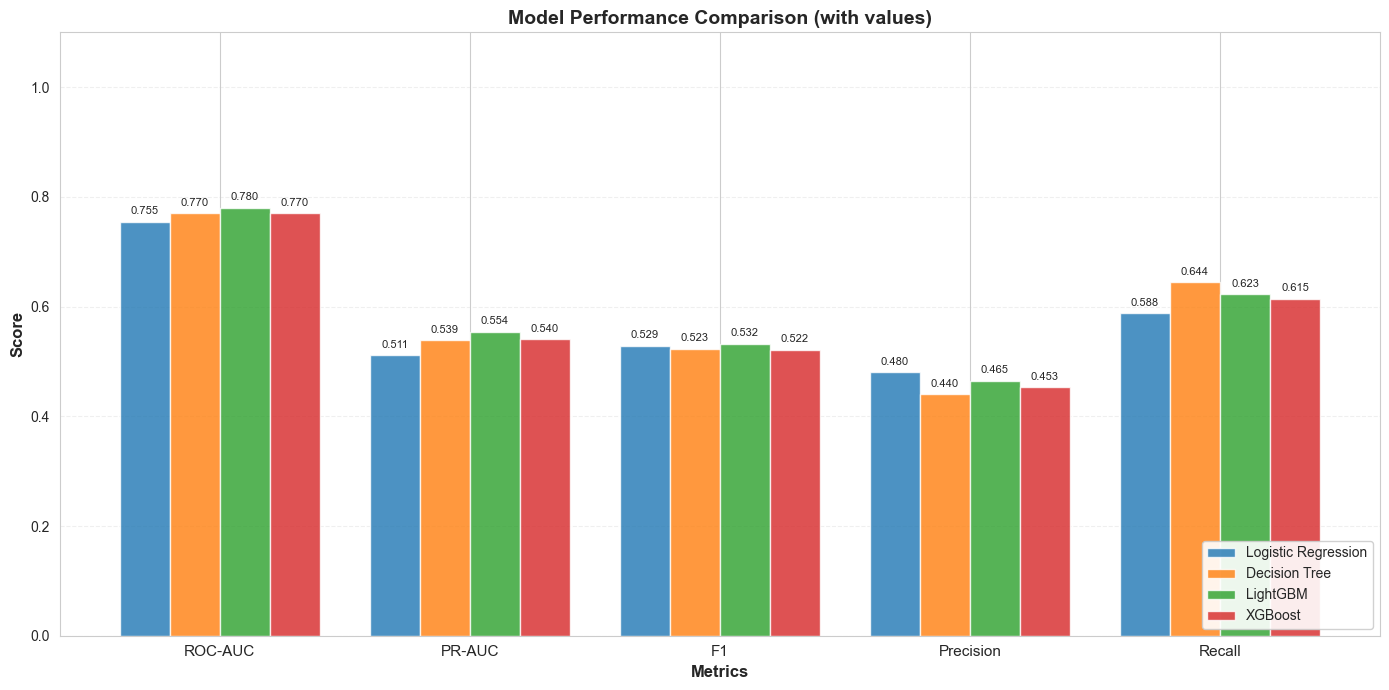

 Saved: q4_09_metrics_comparison.png


In [15]:
# เปรียบเทียบ metric หลักของโมเดลในรูปกราฟ
# Metrics comparison bar chart with value labels
fig, ax = plt.subplots(figsize=(14, 7))

metrics_to_plot = ['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']
x = np.arange(len(metrics_to_plot))
width = 0.2
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, (name, results) in enumerate(models_results.items()):
    row = comparison_df[comparison_df['Model'] == name].iloc[0]
    values = [row[m] for m in metrics_to_plot]
    bars = ax.bar(x + i * width, values, width, label=name, color=colors[i], alpha=0.8)
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f'{value:.3f}',
            ha='center',
            va='bottom',
            fontsize=8,
        )

ax.set_xlabel('Metrics', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Model Performance Comparison (with values)', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_to_plot, fontsize=11)
ax.legend(loc='lower right', fontsize=10, framealpha=0.9)
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('../../report/q4/q4_09_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved: q4_09_metrics_comparison.png")

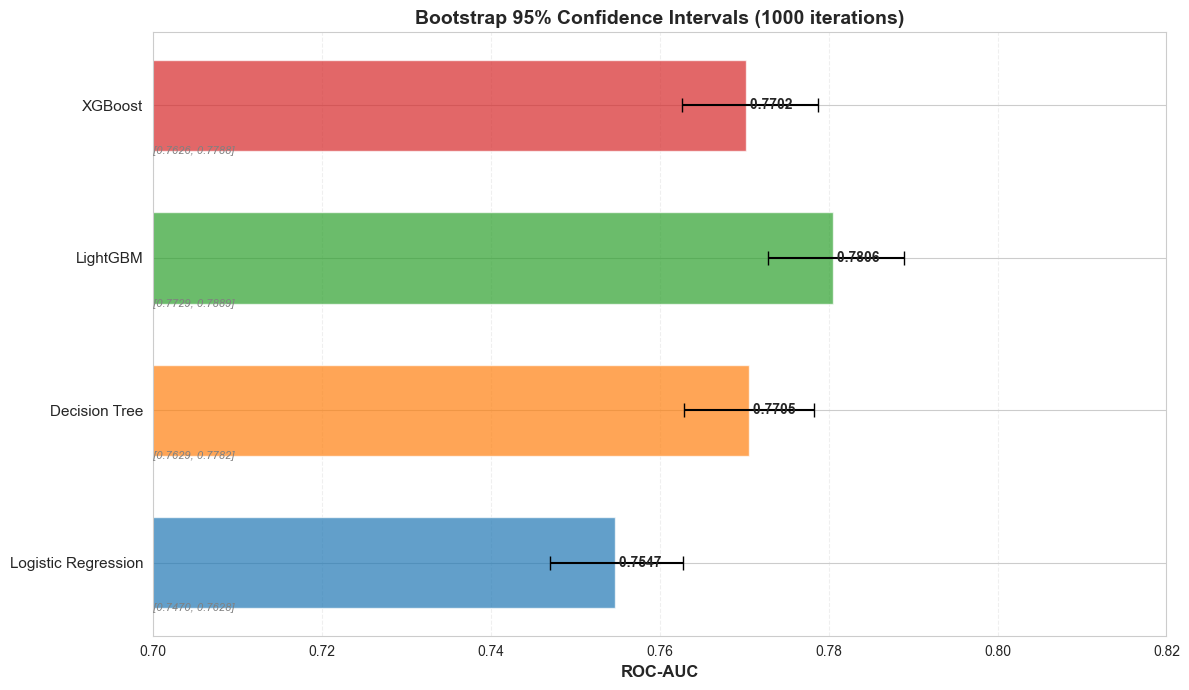

 Saved: q4_10_bootstrap_ci.png


In [16]:
# แสดงค่า ROC-AUC พร้อมช่วงความเชื่อมั่นจาก bootstrap
# Bootstrap CI visualization with improved labels
fig, ax = plt.subplots(figsize=(12, 7))

models = bootstrap_df['Model'].tolist()
means = bootstrap_df['Mean AUC'].tolist()
ci_lower = bootstrap_df['CI Lower'].tolist()
ci_upper = bootstrap_df['CI Upper'].tolist()
errors = [[means[i] - ci_lower[i] for i in range(len(means))],
 [ci_upper[i] - means[i] for i in range(len(means))]]

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
y_pos = np.arange(len(models))

bars = ax.barh(y_pos, means, xerr=errors, color=colors, alpha=0.7, capsize=5, height=0.6)
ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=11)
ax.set_xlabel('ROC-AUC', fontsize=12, fontweight='bold')
ax.set_title('Bootstrap 95% Confidence Intervals (1000 iterations)', 
 fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3, linestyle='--')

# Add value labels (Mean and CI)
for i, (mean, lower, upper) in enumerate(zip(means, ci_lower, ci_upper)):
 # Show mean value at the end of bar
 ax.text(mean, i, f' {mean:.4f}', va='center', ha='left', 
 fontsize=10, fontweight='bold')
 # Show CI range below model name
 ax.text(0.70, i - 0.3, f'[{lower:.4f}, {upper:.4f}]',
 va='center', fontsize=8, style='italic', color='gray')

ax.set_xlim([0.70, 0.82])
plt.tight_layout()
plt.savefig('../../report/q4/q4_10_bootstrap_ci.png', dpi=150, bbox_inches='tight')
plt.show()

print(" Saved: q4_10_bootstrap_ci.png")

## 11. Feature Importance Analysis

In [17]:
# เลือกโมเดลที่มี AUC สูงสุดและดึง feature importance
# Get feature importance from best model (highest AUC)
best_model_name = comparison_df.iloc[0]['Model']
best_model = models_results[best_model_name]['model']

print(f"Best model: {best_model_name}")

# Extract feature importance
if best_model_name == 'Logistic Regression':
 importance = np.abs(best_model.coef_[0])
else: # LightGBM or XGBoost
 importance = best_model.feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({
 'Feature': X_train.columns,
 'Importance': importance
}).sort_values('Importance', ascending=False)

print(f"\nTop 10 Most Important Features ({best_model_name}):")
print(feature_importance_df.head(10).to_string(index=False))

# Save
feature_importance_df.to_csv(os.path.join(RESULTS_OUTPUT_DIR, 'model_feature_importance.csv'), index=False)
print(f"\n Saved: {os.path.join(RESULTS_OUTPUT_DIR, 'model_feature_importance.csv')}")

Best model: LightGBM

Top 10 Most Important Features (LightGBM):
   Feature  Importance
 BILL_AMT1        2111
  PAY_AMT1        1666
 BILL_AMT6        1633
       AGE        1533
 LIMIT_BAL        1507
     PAY_0         446
 EDUCATION         443
NUM_DELAYS         334
     PAY_6         313
     PAY_3         258

 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\results\model_feature_importance.csv


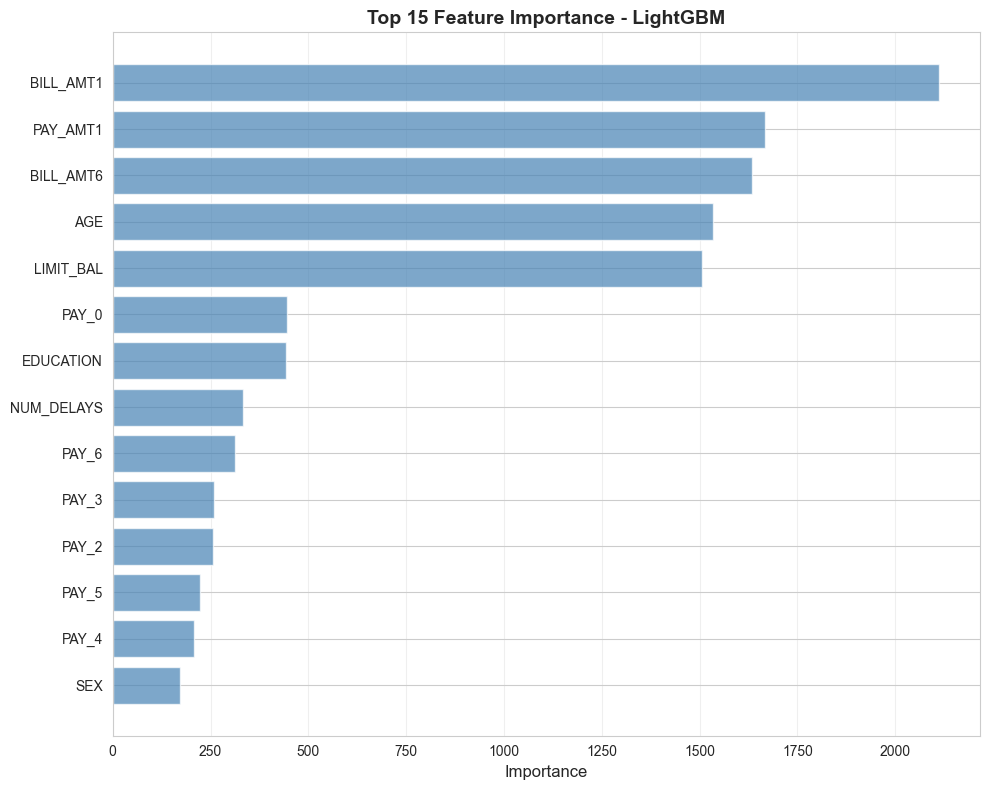

 Saved: q4_11_feature_importance.png


In [18]:
# วาดอันดับ feature ที่โมเดลใช้ในการทำนายมากที่สุด
# Visualize top 15 features
fig, ax = plt.subplots(figsize=(10, 8))

top_15 = feature_importance_df.head(15)
ax.barh(range(len(top_15)), top_15['Importance'], color='steelblue', alpha=0.7)
ax.set_yticks(range(len(top_15)))
ax.set_yticklabels(top_15['Feature'])
ax.set_xlabel('Importance', fontsize=12)
ax.set_title(f'Top 15 Feature Importance - {best_model_name}', 
 fontsize=14, fontweight='bold')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('../../report/q4/q4_11_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(" Saved: q4_11_feature_importance.png")

## 12. Save Models and Results

In [19]:
# บันทึกโมเดลและผลทำนายไว้ใช้ในขั้นประเมินผล
import pickle

models_to_save = {
    'logistic_regression_model.pkl': lr_model,
    'decision_tree_model.pkl': dt_model,
    'lightgbm_model.pkl': lgb_model,
    'xgboost_model.pkl': xgb_model,
    'feature_scaler.pkl': scaler,
}

for filename, model in models_to_save.items():
    with open(os.path.join(MODEL_OUTPUT_DIR, filename), 'wb') as f:
        pickle.dump(model, f)
    print(f" Saved: {os.path.join(MODEL_OUTPUT_DIR, filename)}")

predictions_df = pd.DataFrame({
    'y_true': y_train,
    'lr_proba': models_results['Logistic Regression']['y_proba'],
    'dt_proba': models_results['Decision Tree']['y_proba'],
    'lgb_proba': models_results['LightGBM']['y_proba'],
    'xgb_proba': models_results['XGBoost']['y_proba'],
})
predictions_df.to_csv(os.path.join(RESULTS_OUTPUT_DIR, 'training_oof_predictions.csv'), index=False)
print(f" Saved: {os.path.join(RESULTS_OUTPUT_DIR, 'training_oof_predictions.csv')}")

print("\n" + "=" * 80)
print("MODELING COMPLETE")
print("=" * 80)
print(f"Selected feature set: {best_feature_set} ({len(selected_features)} features)")
print(f"Feature-set CV comparison: {os.path.join(RESULTS_OUTPUT_DIR, 'feature_set_comparison.csv')}")
print(f"Best Model: {best_model_name}")
print(f"OOF ROC-AUC: {comparison_df.iloc[0]['ROC-AUC']:.4f}")
print(f"OOF PR-AUC: {comparison_df.iloc[0]['PR-AUC']:.4f}")
print("\nModels trained:")
for i, row in comparison_df.iterrows():
    print(f" {i + 1}. {row['Model']:20s} - ROC-AUC: {row['ROC-AUC']:.4f}")
print("\nFiles saved:")
print(f" - Results: {RESULTS_OUTPUT_DIR}")
print(f" - Models: {MODEL_OUTPUT_DIR}")
print(" - 4 visualization PNGs (value labels included)")
print("=" * 80)

 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\models\logistic_regression_model.pkl
 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\models\decision_tree_model.pkl
 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\models\lightgbm_model.pkl
 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\models\xgboost_model.pkl
 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\models\feature_scaler.pkl
 Saved: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\results\training_oof_predictions.csv

MODELING COMPLETE
Selected feature set: core_plus_num_delays (14 features)
Feature-set CV comparison: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\results\feature_set_comparison.csv
Best Model: LightGBM
OOF ROC-AUC: 0.7804
OOF PR-AUC: 0.5540

Models trained:
 1. LightGBM             - ROC-AUC: 0.7804
 